# Modelling a 2D function using Multi-Layered Perceptrons

This Notebook will introduce you to:
- How 2D polynomial functions can be modelled with a Multi-Layered Perceptron (MLP).
- The effect of hyperparameters on network performance.
- Different ways to visualise the predictions of networks.

It is recommended to work through the notebook for 1D functions before using this one. Use the code provided and try to get as much performance out of the networks as you can. Only spend 15-30 minutes on this part before moving onto the $\Delta$-ML **Main Task**. 

We want to model the 2D polynomial:

$z=0.8e^{-0.2x}\left(\sin^3{x}\right)+0.6e^{-0.15y}\left(\sin^2{\left(2y\right)}\right)+1.5$

To do this, we need to change our model and data preprocessing to account for 2 dimensions/features in our input vector. Begin running the code and while it trains check to see what was changed to account for 2 input dimensions.

In [1]:
############## PACKAGE IMPORTS ###############
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
############### LOCAL IMPORTS ###############
from network_classes import MLP 
from stats_and_plot_functions import compute_z, sample_xy_values, normalize_data, mean_squared_error, plot_train_loss, calc_num_net_parameters
from stats_and_plot_functions import heatmapplot_subplots, surfaceplot_subplots, heatmapplot, surfaceplot

x_min_max = [-5, 10]
y_min_max = [-8, 8]
dxdy=[0.0001,0.0001]


In [2]:
# Generate uniform grid of x-y values for plotting and validation data

x_values = np.linspace(x_min_max[0], x_min_max[1], 100)
y_values = np.linspace(y_min_max[0], y_min_max[1], 100)
uniform_z = []
uniform_x = []
uniform_y = []
for x in x_values:
    for y in y_values:
        uniform_x.append(x)
        uniform_y.append(y)
        uniform_z.append(compute_z(x,y))
uniform_z = np.array(uniform_z)

# Hyperparameters
training_samples= 40000
learning_rate = 0.001
num_epochs = 100
batch_size = 128
neurons=[100, 50, 20, 10]
activation = [nn.SELU(), nn.ReLU(), nn.Sigmoid()][0]
dropout=0.0 # Leave at 0, currently broken

layers=[] # Format layers for variable MLP class
for n in neurons:
    layers.append((n, activation))
input_dim = 2           # We only have two input dimension (the scalar x and y value)
output_dim = 1          # We only have one output dimension (the scalar z value)
model, optimizer= None,None # Refresh the model and optimiser each time this cell is run
model = MLP(input_dim,output_dim,layers,dropout_prob=dropout)
optimizer = optim.AdamW(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()  

torch.manual_seed(42) # 42 for reproducibility
# Create and preprocess training data into 32 bit floats for PyTorch torch.Tensor objects 
x_vals, y_vals = sample_xy_values(x_min_max, y_min_max, dxdy, training_samples)
z_vals = compute_z(x_vals, y_vals).astype(np.float32)
x_vals_normalized, x_mean, x_std = normalize_data(x_vals)
y_vals_normalized, y_mean, y_std = normalize_data(y_vals)
z_vals_normalized, z_mean, z_std = normalize_data(z_vals)
train_input = torch.tensor(np.concatenate((x_vals_normalized.reshape(len(x_vals_normalized),1),
                            y_vals_normalized.reshape(len(y_vals_normalized),1)), axis=1), device='cpu')
train_target = torch.tensor(z_vals_normalized.reshape(len(z_vals),1), device='cpu')

# Create validation data, which in this case will be the 100x100 uniform grid.
# Note, I am DELIBERATELY using the mean and std from the TRAINING DATA to rescale the validation data
x_uniform_normalized = (((np.array(uniform_x) - x_mean) / x_std).astype(np.float32)).reshape(len(uniform_x),1)
y_uniform_normalized = (((np.array(uniform_y) - y_mean) / y_std).astype(np.float32)).reshape(len(uniform_y),1)
z_uniform_normalized = (((np.array(uniform_z) - z_mean) / z_std).astype(np.float32))
valid_input = torch.tensor(np.concatenate((x_uniform_normalized.reshape(len(x_uniform_normalized),1),
                            y_uniform_normalized.reshape(len(y_uniform_normalized),1)), axis=1), device='cpu')
valid_target_normalized = z_uniform_normalized

# Create DataLoader
train_dataset = TensorDataset(train_input, train_target)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Training loop with validation tracking
train_losses=[]
valid_losses=[]
best_valid_loss, best_train_loss, best_epoch = 1e6, 1e6, 0
best_model_state = None  # To store the best model state dict
for epoch in range(num_epochs):
    total_loss = 0.0
    model.train() # Tell model we are in training mode, weights can be modified, later we switch to evaluation mode
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        batch_X, batch_y = batch_X.float(), batch_y.float()
        outputs = model(batch_X).squeeze()  # squeeze to ensure output shape matches target
        loss = criterion(outputs, batch_y.squeeze())  # Compute loss
        loss.backward()  # Backpropagation
        optimizer.step()  # Update weights
        total_loss += loss.item()
    train_loss = total_loss/len(train_loader)
    
    model.eval() # Important to tell the model we're in evaluation model, ensures no weights are changed by accident
    with torch.no_grad():
        valid_pred_normalised = np.squeeze(model(valid_input).detach().numpy()) # Predict validation data
    valid_loss = mean_squared_error(valid_pred_normalised, valid_target_normalized) # Loss of true norm vs pred norm validation data
    train_losses.append(train_loss), valid_losses.append(valid_loss)
    
    # Save the best model based on validation loss
    if valid_loss < best_valid_loss: 
        best_epoch = epoch
        best_valid_loss, best_train_loss = valid_loss, train_loss
        best_model_state = model.state_dict().copy()  # Save model state
    print(f"Epoch [{epoch+1}/{num_epochs}], Training Loss: {train_loss:.5f}, Valid Loss: {valid_loss:.5f}")
    
print("Training complete.")

Epoch [1/10], Training Loss: 0.57032, Valid Loss: 0.29470
Epoch [2/10], Training Loss: 0.27960, Valid Loss: 0.25821
Epoch [3/10], Training Loss: 0.25958, Valid Loss: 0.27590
Epoch [4/10], Training Loss: 0.25630, Valid Loss: 0.25357
Epoch [5/10], Training Loss: 0.25483, Valid Loss: 0.26132
Epoch [6/10], Training Loss: 0.24880, Valid Loss: 0.24666
Epoch [7/10], Training Loss: 0.24465, Valid Loss: 0.24404
Epoch [8/10], Training Loss: 0.24659, Valid Loss: 0.24902
Epoch [9/10], Training Loss: 0.24377, Valid Loss: 0.24582
Epoch [10/10], Training Loss: 0.24487, Valid Loss: 0.24268
Training complete.



Number of training samples: 40000
Neurons: [100, 50, 20, 10] (6291 parameters) 
Num Epochs: 10 
Learning Rate: 0.001 
Batch Size: 128 
Activation: SELU()
Best model from Epoch 10 restored with Training Loss: 0.24487 and Validation Loss: 0.11453


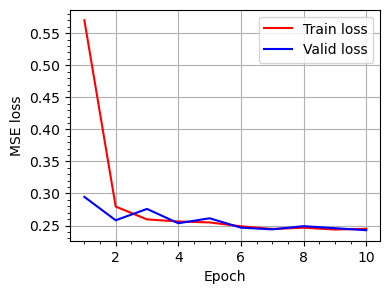

In [3]:
nparams=calc_num_net_parameters(layer_config=neurons.copy())
print("\nNumber of training samples:",training_samples)
print("Neurons:",neurons,"("+str(nparams)+" parameters)","\nNum Epochs:", num_epochs,
      "\nLearning Rate:",learning_rate,"\nBatch Size:",batch_size,"\nActivation:",activation)

valid_pred_normalised = np.squeeze(model(valid_input).detach().numpy())
valid_pred = (valid_pred_normalised * z_std) + z_mean # Unscale the prediction data
valid_loss = mean_squared_error(np.squeeze(valid_pred), np.array(uniform_z))
if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print(f"Best model from Epoch {best_epoch+1} restored with Training Loss: {best_train_loss:.5f} and Validation Loss: {valid_loss:.5f}")

diff = np.squeeze(valid_pred)-np.array(uniform_z).astype(np.float32)  # Deviation between true and predicted data
plot_train_loss(train_losses, valid_losses, figsize=(4,3))


### Visualising Predictions

Below shows heatmaps and contour maps of the true and predicted function for data in the range of $x\in\left[-5,10\right]$ and $y\in\left[-8,8\right]$. Making loss plots and visualising predictions like this helps us to analyse our model performance and identify errors in training, bad hyperparameters, artefacts in the data, or areas where we might need more data.

- Look at the 2D heatmaps, how easy is it to see where the model performs well or not?
- Keep note of the colourbars, is the scale range similar? (fun fact, viridis colour scale is known as a [perceptually uniform colourmap](https://colorcet.com/))
- Computing the deviation makes variation in performance more obvious, what does the scale of the deviation colourbar describe? 
- Now look at the 3D surface plots, do they convey the information better or worse?

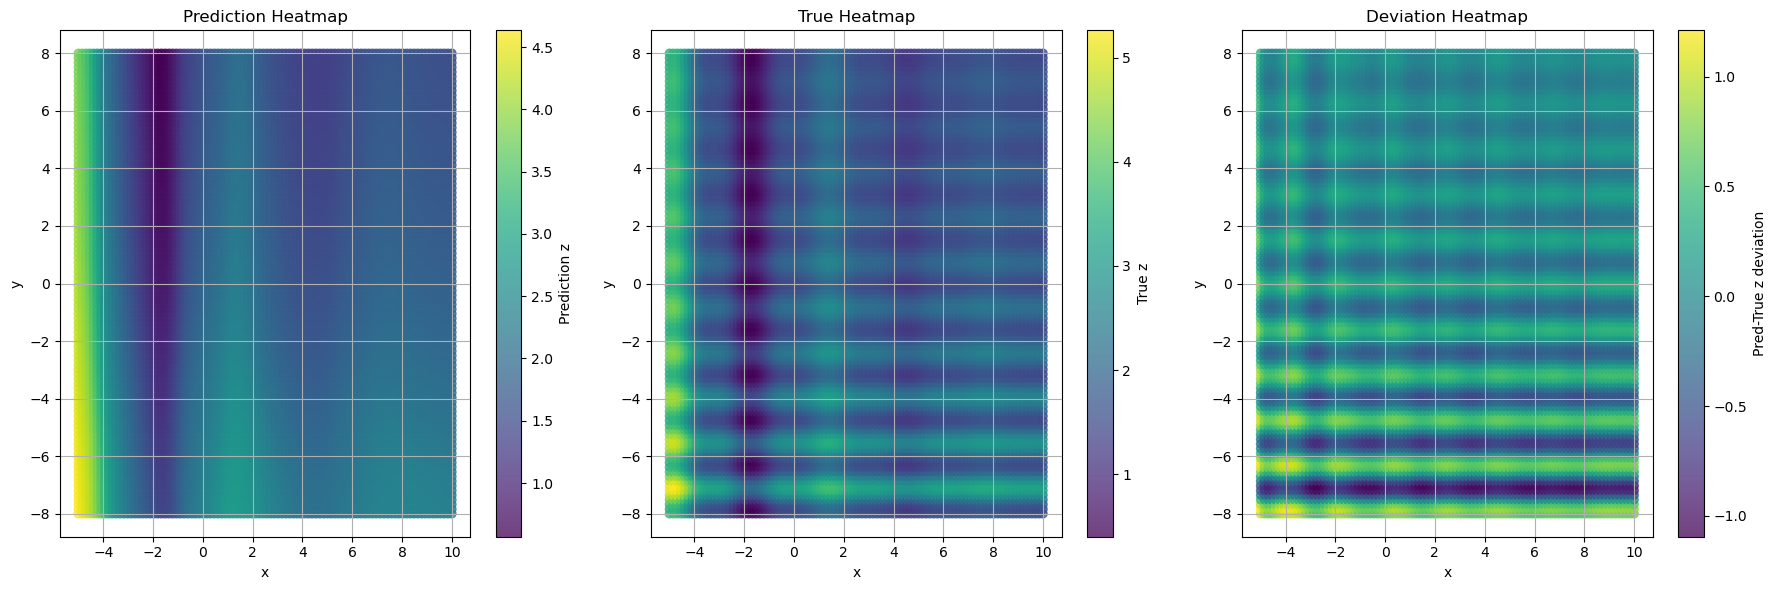

In [4]:

#heatmapplot(uniform_x, uniform_y, np.squeeze(valid_pred), ["x","y","Prediction z", "Prediction Heatmap"])
#heatmapplot(uniform_x, uniform_y, uniform_z, ["x","y","True z", "True Heatmap"])
#heatmapplot(uniform_x, uniform_y, diff, ["x","y","Pred-True z deviation", "Deviation Heatmap"])
heatmapplot_subplots(uniform_x, uniform_y, np.squeeze(valid_pred), uniform_z, diff,
                      ["x", "y", "Prediction z", "Prediction Heatmap"],
                      ["x", "y", "True z", "True Heatmap"],
                      ["x", "y", "Pred-True z deviation", "Deviation Heatmap"])

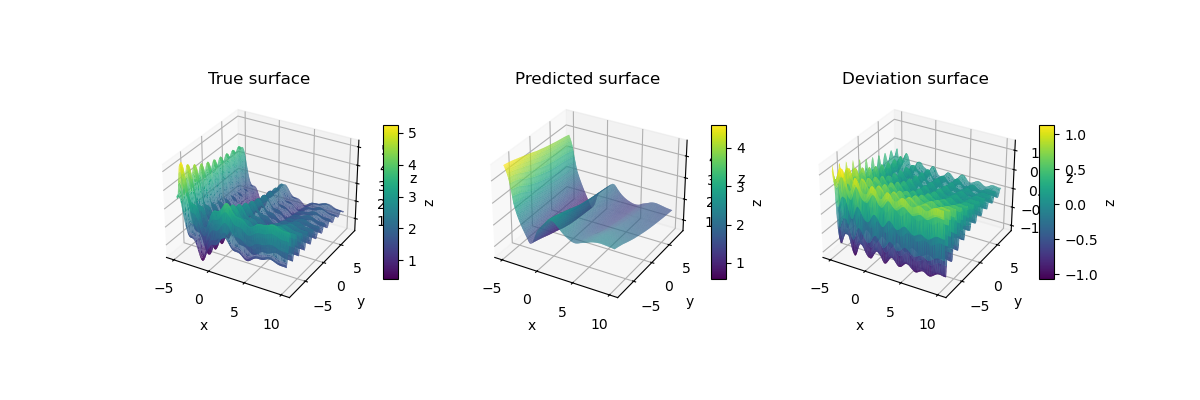

In [5]:
%matplotlib ipympl
#surfaceplot(uniform_x, uniform_y, uniform_z, ["x", "y", "z", "True surface"])
#surfaceplot(uniform_x, uniform_y, np.squeeze(valid_pred), ["x", "y", "z", "Predicted surface"])
#surfaceplot(uniform_x, uniform_y, diff, ["x", "y", "z", "Deviation surface"])

surfaceplot_subplots(uniform_x, uniform_y, uniform_z, np.squeeze(valid_pred), diff,
                      ["x", "y", "z", "True surface"],
                      ["x", "y", "z", "Predicted surface"],
                      ["x", "y", "z", "Deviation surface"], figsize=(12,4))

### Now for $\Delta$-ML

This completes this section. Now you can cannibalise and Frankenstein these code blocks to model some real data! See the dml-brief.docx

See network_models.py, network_models_2D.p, network_classes.py and stats_and_plot_functions for full solutions.

## Extensions
Can you think of how you would solve these or how it would change the problem? You can try these in your own time:

- In reality, data is often noisy. Try adding noise to the simulated data. See [this](https://medium.com/@mfbenedetto/visualizing-function-approximation-using-dense-neural-networks-in-1d-part-i-1c3bdc51dc02) and [that](https://medium.com/@mfbenedetto/visualizing-function-approximation-using-dense-neural-networks-in-1d-part-ii-9ec29752fcda) post.

- Implement k-fold cross-validation and average their losses to get a mean and standard deviation for the validation data.

- If you were to makeup some 5D distribution of data, how could you visualise model performance?

- Try parallel processing over different folds or repeats of the networks with different random initialisations of the training parameters (by modifying the random seed when initialising the MLP class). This can give you a *mean* loss and *std deviation*, which is more useful than just a loss (why?).

